<a href="https://colab.research.google.com/github/iputuwidia75-ux/Ni-putu-widia-novita-kirani-/blob/main/peta_ulasan_warung_denpasar_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Peta dan Ulasan Warung Kuliner Denpasar
Perencanaan data multimedia: jenis data, karakteristik, asumsi volume, dan estimasi storage.

**Nama:** ................  **NIM:** ................  **Tanggal:** ................

> Dibuat untuk Google Colab. Unggah ke GitHub lewat **File → Save a copy in GitHub**.

## 1. Daftar Jenis Data yang Dibutuhkan

In [1]:
import pandas as pd
pd.set_option("display.max_colwidth", None)

jenis = pd.DataFrame({
    "No": [1, 2, 3, 4],
    "Jenis data": ["Teks", "Gambar", "Audio", "Spasial"],
    "Contoh pada aplikasi peta dan ulasan warung Denpasar": [
        "Ulasan pengunjung, rating, nama warung, alamat, menu, jam buka",
        "Foto makanan, foto tempat/warung, foto menu",
        "Ulasan suara pengguna, rekaman wawancara pemilik warung",
        "Koordinat lokasi warung (titik), batas kecamatan, rute jalan",
    ],
    "Fungsi dalam sistem": [
        "Isi utama ulasan dan informasi warung",
        "Bukti visual dan daya tarik warung",
        "Alternatif input ulasan dan dokumentasi cerita warung",
        "Menampilkan warung pada peta dan pencarian 'terdekat'",
    ],
}).set_index("No")
jenis

,Jenis data,Contoh pada aplikasi peta dan ulasan warung Denpasar,Fungsi dalam sistem
No,,,
1,Teks,"Ulasan pengunjung, rating, nama warung, alamat, menu, jam buka",Isi utama ulasan dan informasi warung
2,Gambar,"Foto makanan, foto tempat/warung, foto menu",Bukti visual dan daya tarik warung
3,Audio,"Ulasan suara pengguna, rekaman wawancara pemilik warung",Alternatif input ulasan dan dokumentasi cerita warung
4,Spasial,"Koordinat lokasi warung (titik), batas kecamatan, rute jalan",Menampilkan warung pada peta dan pencarian 'terdekat'


In [2]:
pertanyaan = [
    "1. Apa bentuk/format datanya?",
    "2. Bagaimana strukturnya?",
    "3. Dari mana sumber dan cara perolehannya?",
    "4. Berapa ukuran tipikalnya?",
    "5. Bagaimana cara menyimpan dan mencarinya?",
    "6. Apa tantangan utamanya?",
]
karakter = pd.DataFrame({
    "Pertanyaan": pertanyaan,
    "Teks": [
        ".txt, .json, .csv; kolom VARCHAR/TEXT",
        "Terstruktur / semi-terstruktur",
        "Formulir ulasan di aplikasi, survei, input pemilik warung",
        "Sekitar 1 KB per ulasan",
        "Tabel basis data relasional; indeks B-tree dan full-text search",
        "Bahasa campuran (Indonesia, Inggris, Bali), typo, ulasan spam",
    ],
    "Gambar": [
        ".jpg, .png, .webp",
        "Tidak terstruktur (matriks piksel) + metadata EXIF",
        "Unggahan pengguna dan foto surveyor",
        "Sekitar 2 MB per foto (setelah kompresi)",
        "Object storage/file system; metadata dan URL di basis data",
        "Ukuran besar, kualitas bervariasi, hak cipta, moderasi konten",
    ],
    "Audio": [
        ".mp3, .m4a, .wav",
        "Tidak terstruktur (deret waktu gelombang suara)",
        "Rekaman di aplikasi dan wawancara lapangan",
        "Sekitar 1 MB per klip 60 detik",
        "Object storage; transkrip teks disimpan di basis data untuk pencarian",
        "Noise pasar/jalan, dialek, privasi suara, durasi",
    ],
    "Spasial": [
        "GeoJSON, Shapefile, WKT; titik, garis, poligon",
        "Terstruktur (geometri + atribut)",
        "GPS perangkat, OpenStreetMap, survei lapangan",
        "Sekitar 5 KB per fitur",
        "PostgreSQL + PostGIS; indeks spasial GiST/R-tree",
        "Akurasi GPS, sistem koordinat (WGS84), data lokasi cepat usang",
    ],
}).set_index("Pertanyaan")
karakter

,Teks,Gambar,Audio,Spasial
Pertanyaan,,,,
1. Apa bentuk/format datanya?,".txt, .json, .csv; kolom VARCHAR/TEXT",".jpg, .png, .webp",".mp3, .m4a, .wav","GeoJSON, Shapefile, WKT; titik, garis, poligon"
2. Bagaimana strukturnya?,Terstruktur / semi-terstruktur,Tidak terstruktur (matriks piksel) + metadata EXIF,Tidak terstruktur (deret waktu gelombang suara),Terstruktur (geometri + atribut)
3. Dari mana sumber dan cara perolehannya?,"Formulir ulasan di aplikasi, survei, input pemilik warung",Unggahan pengguna dan foto surveyor,Rekaman di aplikasi dan wawancara lapangan,"GPS perangkat, OpenStreetMap, survei lapangan"
4. Berapa ukuran tipikalnya?,Sekitar 1 KB per ulasan,Sekitar 2 MB per foto (setelah kompresi),Sekitar 1 MB per klip 60 detik,Sekitar 5 KB per fitur
5. Bagaimana cara menyimpan dan mencarinya?,Tabel basis data relasional; indeks B-tree dan full-text search,Object storage/file system; metadata dan URL di basis data,Object storage; transkrip teks disimpan di basis data untuk pencarian,PostgreSQL + PostGIS; indeks spasial GiST/R-tree
6. Apa tantangan utamanya?,"Bahasa campuran (Indonesia, Inggris, Bali), typo, ulasan spam","Ukuran besar, kualitas bervariasi, hak cipta, moderasi konten","Noise pasar/jalan, dialek, privasi suara, durasi","Akurasi GPS, sistem koordinat (WGS84), data lokasi cepat usang"


## 3. Ekstraksi Metadata Keempat Jenis Data



In [3]:
import os, json, wave, struct, math, random
from PIL import Image, ImageDraw
from PIL.ExifTags import TAGS

os.makedirs("sampel_data", exist_ok=True)

# --- Data contoh: TEKS ---
ulasan = [
    {"id": 1, "warung": "Warung Nasi Ayam Kedewatan", "rating": 5,
     "isi": "Ayam betutu-nya enak banget, sambal matahnya segar. Harga murah dan pelayanan cepat!"},
    {"id": 2, "warung": "Warung Babi Guling Renon", "rating": 4,
     "isi": "Babi gulingnya gurih, tapi antrean agak panjang saat jam makan siang."},
]
with open("sampel_data/ulasan.json", "w", encoding="utf-8") as f:
    json.dump(ulasan, f, ensure_ascii=False, indent=2)

# --- Data contoh: GAMBAR ---
img = Image.new("RGB", (1280, 960), (230, 160, 60))
ImageDraw.Draw(img).text((40, 40), "Foto contoh: nasi campur", fill=(0, 0, 0))
exif = Image.Exif()
exif[0x010F] = "Kamera Contoh"        # Make
exif[0x0110] = "Model-X"              # Model
exif[0x0132] = "2026:10:21 12:30:00"  # DateTime
img.save("sampel_data/foto_makanan.jpg", quality=85, exif=exif)

# --- Data contoh: AUDIO (nada sinus 5 detik, 16-bit mono 22,05 kHz) ---
sr, dur = 22050, 5
with wave.open("sampel_data/ulasan_suara.wav", "wb") as w:
    w.setnchannels(1); w.setsampwidth(2); w.setframerate(sr)
    frames = b"".join(struct.pack("<h", int(12000*math.sin(2*math.pi*440*t/sr))) for t in range(sr*dur))
    w.writeframes(frames)

# --- Data contoh: SPASIAL (GeoJSON titik warung di Denpasar) ---
geojson = {
    "type": "FeatureCollection",
    "crs": {"type": "name", "properties": {"name": "EPSG:4326"}},
    "features": [
        {"type": "Feature", "properties": {"nama": "Warung Babi Guling Renon", "rating": 4.0},
         "geometry": {"type": "Point", "coordinates": [115.2377, -8.6705]}},
        {"type": "Feature", "properties": {"nama": "Warung Nasi Ayam Kedewatan", "rating": 4.6},
         "geometry": {"type": "Point", "coordinates": [115.2169, -8.6360]}},
        {"type": "Feature", "properties": {"nama": "Warung Sanur", "rating": 4.2},
         "geometry": {"type": "Point", "coordinates": [115.2630, -8.6780]}},
    ],
}
with open("sampel_data/warung.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson, f)

print("Data contoh dibuat:", os.listdir("sampel_data"))

Data contoh dibuat: ['ulasan.json', 'warung.geojson', 'ulasan_suara.wav', 'foto_makanan.jpg']


In [4]:
def metadata_teks(path):
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    teks = " ".join(d["isi"] for d in data)
    return {
        "berkas": os.path.basename(path), "jenis": "Teks",
        "ukuran_byte": os.path.getsize(path),
        "jumlah_record": len(data),
        "jumlah_karakter": len(teks),
        "jumlah_kata": len(teks.split()),
        "encoding": "UTF-8",
        "kolom": ", ".join(data[0].keys()),
        "rata2_rating": sum(d["rating"] for d in data) / len(data),
    }

def metadata_gambar(path):
    with Image.open(path) as im:
        exif = {TAGS.get(k, k): v for k, v in im.getexif().items()}
        return {
            "berkas": os.path.basename(path), "jenis": "Gambar",
            "ukuran_byte": os.path.getsize(path),
            "format": im.format, "mode_warna": im.mode,
            "lebar_px": im.width, "tinggi_px": im.height,
            "megapiksel": round(im.width * im.height / 1e6, 2),
            "exif_make": exif.get("Make"), "exif_model": exif.get("Model"),
            "exif_datetime": exif.get("DateTime"),
        }

def metadata_audio(path):
    with wave.open(path, "rb") as w:
        n, sr, ch, sw = w.getnframes(), w.getframerate(), w.getnchannels(), w.getsampwidth()
    return {
        "berkas": os.path.basename(path), "jenis": "Audio",
        "ukuran_byte": os.path.getsize(path),
        "format": "WAV (PCM)", "kanal": ch, "sample_rate_hz": sr,
        "bit_depth": sw * 8, "durasi_detik": round(n / sr, 2),
        "bitrate_kbps": round(sr * sw * 8 * ch / 1000, 1),
    }

def metadata_spasial(path):
    with open(path, encoding="utf-8") as f:
        gj = json.load(f)
    pts = [ft["geometry"]["coordinates"] for ft in gj["features"]]
    lons, lats = [p[0] for p in pts], [p[1] for p in pts]
    return {
        "berkas": os.path.basename(path), "jenis": "Spasial",
        "ukuran_byte": os.path.getsize(path),
        "format": "GeoJSON", "crs": gj["crs"]["properties"]["name"],
        "tipe_geometri": ", ".join(sorted({ft["geometry"]["type"] for ft in gj["features"]})),
        "jumlah_fitur": len(gj["features"]),
        "bbox_(minLon,minLat,maxLon,maxLat)": (min(lons), min(lats), max(lons), max(lats)),
        "atribut": ", ".join(gj["features"][0]["properties"].keys()),
    }

hasil = [
    metadata_teks("sampel_data/ulasan.json"),
    metadata_gambar("sampel_data/foto_makanan.jpg"),
    metadata_audio("sampel_data/ulasan_suara.wav"),
    metadata_spasial("sampel_data/warung.geojson"),
]

# Tampilkan metadata per jenis (kolom berbeda tiap jenis, jadi ditampilkan terpisah)
for h in hasil:
    print(f"=== {h['jenis']}: {h['berkas']} ===")
    display(pd.Series(h, name="nilai").to_frame())

=== Teks: ulasan.json ===


,nilai
berkas,ulasan.json
jenis,Teks
ukuran_byte,347
jumlah_record,2
jumlah_karakter,154
jumlah_kata,23
encoding,UTF-8
kolom,"id, warung, rating, isi"
rata2_rating,4.5


=== Gambar: foto_makanan.jpg ===


,nilai
berkas,foto_makanan.jpg
jenis,Gambar
ukuran_byte,21111
format,JPEG
mode_warna,RGB
lebar_px,1280
tinggi_px,960
megapiksel,1.23
exif_make,Kamera Contoh
exif_model,Model-X


=== Audio: ulasan_suara.wav ===


,nilai
berkas,ulasan_suara.wav
jenis,Audio
ukuran_byte,220544
format,WAV (PCM)
kanal,1
sample_rate_hz,22050
bit_depth,16
durasi_detik,5.0
bitrate_kbps,352.8


=== Spasial: warung.geojson ===


,nilai
berkas,warung.geojson
jenis,Spasial
ukuran_byte,557
format,GeoJSON
crs,EPSG:4326
tipe_geometri,Point
jumlah_fitur,3
"bbox_(minLon,minLat,maxLon,maxLat)","(115.2169, -8.678, 115.263, -8.636)"
atribut,"nama, rating"


In [5]:
# Ringkasan lintas jenis: ukuran berkas contoh
ringkas = pd.DataFrame([{"Jenis": h["jenis"], "Berkas": h["berkas"], "Ukuran (KB)": round(h["ukuran_byte"]/1024, 2)} for h in hasil])
display(ringkas)

,Jenis,Berkas,Ukuran (KB)
0,Teks,ulasan.json,0.34
1,Gambar,foto_makanan.jpg,20.62
2,Audio,ulasan_suara.wav,215.38
3,Spasial,warung.geojson,0.54


**Catatan analisis:** metadata teks dan spasial berupa statistik isi dan struktur. Metadata gambar dan audio berupa parameter teknis (resolusi, sample rate, durasi) yang menentukan ukuran berkas, sehingga langsung dipakai untuk menurunkan asumsi ukuran rata-rata pada bagian 4. Contoh: WAV tanpa kompresi bitrate-nya 352,8 kbps (sekitar 2,5 MB per 60 detik), sedangkan asumsi 1 MB per klip 60 detik setara audio terkompresi (MP3/M4A) sekitar 128 kbps.

## 4. Asumsi Jumlah Unit dan Ukuran Rata-rata

Asumsi untuk **bulan ke-1**, dengan pertumbuhan **10% per bulan** selama 12 bulan.

In [6]:
asumsi = pd.DataFrame({
    "Jenis data": ["Teks", "Gambar", "Audio", "Spasial"],
    "Satuan unit": ["ulasan", "foto", "klip audio (60 dtk)", "fitur lokasi"],
    "Jumlah unit bulan ke-1": [2000, 1000, 200, 300],
    "Ukuran rata-rata per unit (KB)": [1, 2048, 1024, 5],
})
asumsi["Total bulan ke-1 (MB)"] = (
    asumsi["Jumlah unit bulan ke-1"] * asumsi["Ukuran rata-rata per unit (KB)"] / 1024
).round(2)
asumsi["Ukuran per unit"] = ["1 KB", "2 MB", "1 MB", "5 KB"]
display(asumsi.set_index("Jenis data"))

PERTUMBUHAN = 0.10   # 10% per bulan
BULAN = 12
CADANGAN = 0.30      # cadangan 30%

,Satuan unit,Jumlah unit bulan ke-1,Ukuran rata-rata per unit (KB),Total bulan ke-1 (MB),Ukuran per unit
Jenis data,,,,,
Teks,ulasan,2000,1,1.95,1 KB
Gambar,foto,1000,2048,2000.00,2 MB
Audio,klip audio (60 dtk),200,1024,200.00,1 MB
Spasial,fitur lokasi,300,5,1.46,5 KB


## 5. Estimasi Total Storage 1 Tahun + Cadangan 30%

Ukuran bulan ke-*m* = ukuran bulan ke-1 × 1,1^(m−1). Total storage = jumlah 12 bulan, lalu ditambah 30% untuk cadangan.

In [7]:
import matplotlib.pyplot as plt

base = dict(zip(asumsi["Jenis data"], asumsi["Total bulan ke-1 (MB)"]))
rows = []
for m in range(1, BULAN + 1):
    f = (1 + PERTUMBUHAN) ** (m - 1)
    r = {"Bulan": m}
    for j, mb in base.items():
        r[j + " (MB)"] = mb * f
    rows.append(r)
df = pd.DataFrame(rows).set_index("Bulan")
df["Total bulan (MB)"] = df.sum(axis=1)
df["Kumulatif (GB)"] = df["Total bulan (MB)"].cumsum() / 1024
display(df.round(2))

# Rekap per jenis
rekap = df[[c for c in df.columns if c.endswith("(MB)") and "Total" not in c]].sum()
rekap.index = [i.replace(" (MB)", "") for i in rekap.index]
tabel = pd.DataFrame({"Total 12 bulan (MB)": rekap})
tabel["Total 12 bulan (GB)"] = tabel["Total 12 bulan (MB)"] / 1024
tabel["Persentase (%)"] = tabel["Total 12 bulan (MB)"] / tabel["Total 12 bulan (MB)"].sum() * 100
display(tabel.round(2))

total_data_mb = tabel["Total 12 bulan (MB)"].sum()
cadangan_mb = total_data_mb * CADANGAN
total_akhir_mb = total_data_mb + cadangan_mb

print(f"Total data 1 tahun            : {total_data_mb:>12,.0f} MB = {total_data_mb/1024:6.2f} GB")
print(f"Cadangan 30%                  : {cadangan_mb:>12,.0f} MB = {cadangan_mb/1024:6.2f} GB")
print(f"TOTAL STORAGE + CADANGAN 30%  : {total_akhir_mb:>12,.0f} MB = {total_akhir_mb/1024:6.2f} GB")

,Teks (MB),Gambar (MB),Audio (MB),Spasial (MB),Total bulan (MB),Kumulatif (GB)
Bulan,,,,,,
1,1.95,2000.00,200.00,1.46,2203.41,2.15
2,2.14,2200.00,220.00,1.61,2423.75,4.52
3,2.36,2420.00,242.00,1.77,2666.13,7.12
4,2.60,2662.00,266.20,1.94,2932.74,9.99
5,2.85,2928.20,292.82,2.14,3226.01,13.14
6,3.14,3221.02,322.10,2.35,3548.61,16.60
7,3.45,3543.12,354.31,2.59,3903.48,20.41
8,3.80,3897.43,389.74,2.85,4293.82,24.61
9,4.18,4287.18,428.72,3.13,4723.21,29.22


,Total 12 bulan (MB),Total 12 bulan (GB),Persentase (%)
Teks,41.70,0.04,0.09
Gambar,42768.57,41.77,90.77
Audio,4276.86,4.18,9.08
Spasial,31.22,0.03,0.07


Total data 1 tahun            :       47,118 MB =  46.01 GB
Cadangan 30%                  :       14,136 MB =  13.80 GB
TOTAL STORAGE + CADANGAN 30%  :       61,254 MB =  59.82 GB


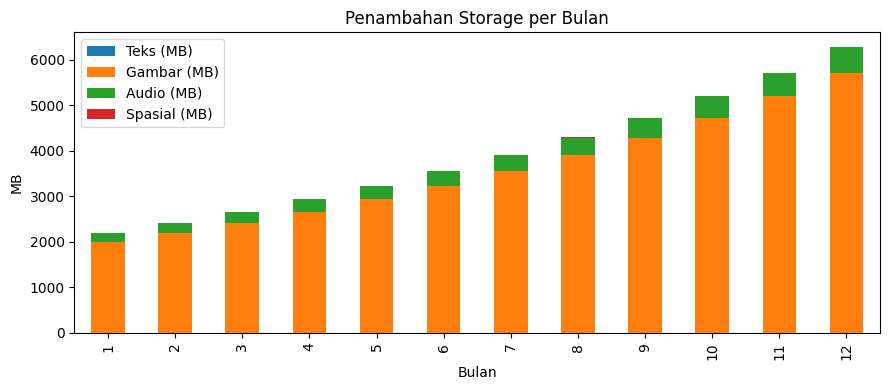

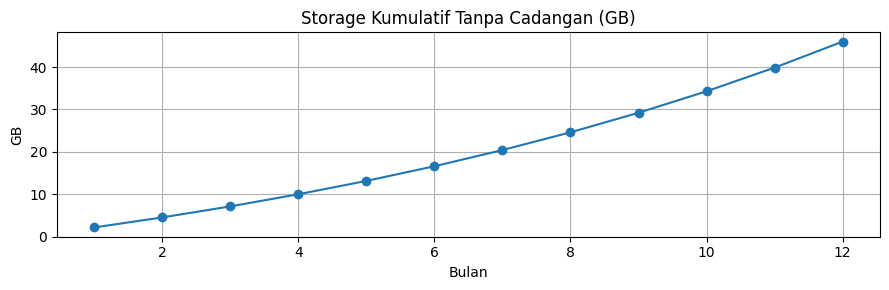

In [8]:
df[[c for c in df.columns if c.endswith("(MB)") and "Total" not in c]].plot(
    kind="bar", stacked=True, figsize=(9, 4))
plt.title("Penambahan Storage per Bulan"); plt.ylabel("MB")
plt.tight_layout(); plt.show()

(df["Kumulatif (GB)"]).plot(marker="o", figsize=(9, 3), title="Storage Kumulatif Tanpa Cadangan (GB)")
plt.ylabel("GB"); plt.grid(True); plt.tight_layout(); plt.show()

**Hasil ringkas:** total data 12 bulan sekitar **46,0 GB**, cadangan 30% sekitar **13,8 GB**, sehingga kebutuhan total sekitar **59,8 GB** (dibulatkan: siapkan kapasitas 60 GB atau lebih).

Foto mendominasi lebih dari 90% storage, sehingga kompresi gambar paling berpengaruh pada penghematan.